<h1>CME538 - Introduction to Data Science</h1>
<h2>Lecture 5.3 - Gradient Descent I</h2>
<p>The previous lecture searched a grid of candidate predictions. Gradient descent uses derivatives to update parameters. The tips examples retain their constant, one-parameter and two-parameter models, followed by a constructed sensor example.</p><p>Central question: how does the gradient turn the current parameters into a better fit?</p><p>After this notebook, you should read a gradient, carry out an update, interpret a loss history, and connect scaling and parameter count with the optimization path.</p>
<a id="lecture-structure"></a><h3>Lecture Structure</h3><ol><li><a href="#section1">Import Tips Data</a></li><li><a href="#section2">Gradient Descent</a></li><li><a href="#section3">1D Gradient Descent</a></li><li><a href="#section4">2D Gradient Descent (Unscaled)</a></li><li><a href="#section5">2D Gradient Descent (Scaled)</a></li></ol>
<p><a href="#lecture-summary">Lecture summary</a></p>
<h3>Optional extensions</h3><ol start="6"><li><a href="#section6">Inspect each update and learning rate</a></li><li><a href="#section7">Fit a sensor response</a></li><li><a href="#section8">Extend the gradient to several features</a></li></ol>
<p>Run Setup Notebook first, then run the sections in order. The main section numbers match the slide handoffs.</p>
<h3>Sources and documentation</h3><p><a href="../slides/week5_lecture3.pptx">Lecture slides</a> | <a href="DATA_SOURCES.html">Dataset sources and fields</a> | <a href="https://numpy.org/doc/stable/reference/generated/numpy.mean.html">NumPy means</a> | <a href="https://ipywidgets.readthedocs.io/en/latest/examples/Using%20Interact.html">Notebook sliders</a></p>

<h2>Setup Notebook</h2><p>The course environment supplies NumPy, pandas, Matplotlib and Seaborn, plus ipywidgets for the sliders. All datasets are local. Plot layouts live in <a href="utils.py">utils.py</a>. Loss functions, gradients, parameter updates and optimization loops remain visible below.</p>

In [1]:
import numpy as np
import pandas as pd
from ipywidgets import interact, fixed, IntSlider

import utils

%matplotlib inline
RANDOM_STATE = 538
utils.configure_plots()
pd.set_option('display.max_columns', 8)
pd.set_option('display.max_rows', 10)

<a id="Import-Tips-Data"></a>
<a id="section1"></a><h2>1. Import Tips Data</h2><p>Question: what does one restaurant bill tell us about tip percentages?</p>

<h3>Load the same classroom sample</h3><p>The local tips table contains one row per restaurant bill. Keep the first 243 rows, matching the existing slide examples. This sample describes one restaurant context rather than all restaurant customers.</p>

In [2]:
tips = pd.read_csv('tips.csv').iloc[:-1].copy()
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<h3>Calculate the response</h3><p>Divide the tip by the bill and multiply by 100. A constant model predicts the same percentage for every bill.</p>

In [3]:
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100
tips[['total_bill', 'tip', 'tip_pct']].head()

,total_bill,tip,tip_pct
0,16.99,1.01,5.944673
1,10.34,1.66,16.054159
2,21.01,3.50,16.658734
3,23.68,3.31,13.978041
4,24.59,3.61,14.680765


<h3>Inspect the target distribution</h3><p>The first model predicts one constant tip percentage. Later models predict tip amounts from bills. These are different response variables with different units.</p>

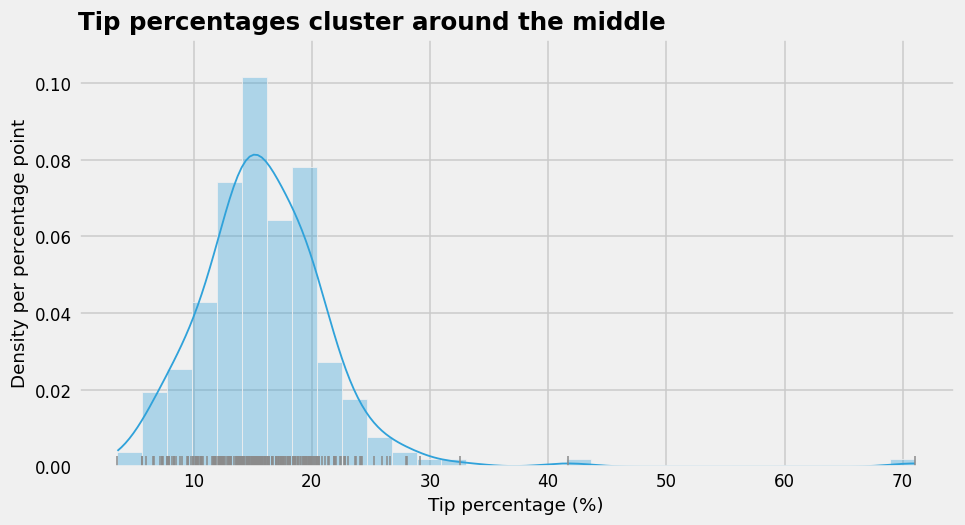

In [4]:
utils.plot_tips(tips['tip_pct'])

<p>Takeaway: Name the response before defining the loss. Percentage and dollar predictions solve different fitting problems.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="Gradient-Descent"></a>
<a id="section2"></a><h2>2. Gradient Descent</h2><p>Question: how do repeated gradient updates change a constant prediction?</p>

<h3>Define the loss and its derivative</h3><p>The gradient is the derivative of the average loss with respect to the current constant. A negative gradient increases the next parameter value under the subtraction rule.</p>

<p>$$L(\theta)=\frac{1}{n}\sum_i(y_i-\theta)^2,\qquad L\prime(\theta)=-2\,\operatorname{mean}(y-\theta).$$</p><p>The update is <code>theta = theta - alpha * gradient</code>. The learning rate <code>alpha</code> multiplies the local slope.</p>

In [5]:
def mse_constant(theta, y_vals):
    return np.mean((y_vals - theta)**2)

def grad_mse_constant(theta, y_vals):
    return -2 * np.mean(y_vals - theta)

<h3>Keep the optimization loop visible</h3><p>Start at zero, evaluate the loss, calculate the gradient, and update the parameter. The stopping rule uses a parameter change below 0.001. A finite iteration limit prevents an endless run for unsuitable settings. Printed checkpoints keep the progress readable.</p>

In [6]:
def minimize(loss_fn, grad_loss_fn, dataset, alpha=0.2, progress=True, max_steps=10000):
    theta = 0.0
    for step in range(max_steps):
        loss = loss_fn(theta, dataset)
        gradient = grad_loss_fn(theta, dataset)
        new_theta = theta - alpha * gradient
        converged = abs(new_theta - theta) < 0.001
        if progress and (step < 5 or step % 10 == 0 or converged):
            print(f'step {step:3d} | theta {theta:8.4f} | loss {loss:8.4f}')
        if not np.isfinite(new_theta):
            raise ValueError('The parameter diverged. Reduce the learning rate.')
        if converged:
            return new_theta
        theta = new_theta
    raise RuntimeError('The stopping rule was not reached within max_steps.')

<h3>Compare the original learning rates</h3><p>Both runs use the same data and initial value. The larger rate overshoots the optimum and alternates sides, while remaining stable for this particular constant-model MSE.</p>

In [7]:
theta = minimize(mse_constant, grad_mse_constant, tips['tip_pct'].to_numpy(), alpha=0.2)
print(f'Final constant: {theta:.4f}% | sample mean: {tips.tip_pct.mean():.4f}%')

step   0 | theta   0.0000 | loss 295.8868
step   1 | theta   6.4323 | loss 130.3900
step   2 | theta  10.2916 | loss  70.8112
step   3 | theta  12.6073 | loss  49.3628
step   4 | theta  13.9966 | loss  41.6414
step  10 | theta  15.9835 | loss  37.3075
step  18 | theta  16.0791 | loss  37.2981
Final constant: 16.0797% | sample mean: 16.0807%


In [8]:
theta = minimize(mse_constant, grad_mse_constant, tips['tip_pct'].to_numpy(), alpha=0.9)
print(f'Final constant: {theta:.4f}% | sample mean: {tips.tip_pct.mean():.4f}%')

step   0 | theta   0.0000 | loss 295.8868
step   1 | theta  28.9452 | loss 202.7949
step   2 | theta   5.7890 | loss 143.2160
step   3 | theta  24.3140 | loss 105.0856
step   4 | theta   9.4940 | loss  80.6821
step  10 | theta  14.3540 | loss  40.2794
step  20 | theta  15.8953 | loss  37.3325
step  30 | theta  16.0608 | loss  37.2985
step  40 | theta  16.0786 | loss  37.2981
step  47 | theta  16.0811 | loss  37.2981
Final constant: 16.0803% | sample mean: 16.0807%


<p>A small parameter change is a stopping criterion rather than a universal accuracy guarantee. The known sample mean provides an independent check here.</p>

<h3>Record every update for the slider</h3><p>The next function records the initial value and every updated value. Losses and gradients are evaluated at those same parameters, so the plotted tangent and loss agree with the displayed step.</p>

In [9]:
def trace_constant(steps, loss_fn, grad_loss_fn, dataset, alpha=0.2, start=90.0):
    theta = float(start)
    path = [theta]
    for _ in range(steps):
        gradient = grad_loss_fn(theta, dataset)
        theta = theta - alpha * gradient
        path.append(theta)
    losses = np.array([loss_fn(t, dataset) for t in path])
    gradients = np.array([grad_loss_fn(t, dataset) for t in path])
    return np.array(path), losses, gradients

<p>The slider retains the original 1.01 learning rate and starting value of 90. This rate deliberately diverges. The plotting helper only draws the values calculated below.</p>

In [10]:
def show_constant(epochs):
    path, losses, gradients = trace_constant(epochs, mse_constant,
        grad_mse_constant, tips['tip_pct'].to_numpy(), alpha=1.01)
    grid = np.linspace(min(path)-10, max(path)+10, 250)
    curve = [mse_constant(t, tips['tip_pct'].to_numpy()) for t in grid]
    utils.plot_scalar_path(path, losses, gradients, grid, curve)

interact(show_constant, epochs=IntSlider(value=1, min=1, max=100, continuous_update=False));

interactive(children=(IntSlider(value=1, continuous_update=False, description='epochs', min=1), Output()), _do…

<p>The saved view below shows 20 updates even in a viewer without widget support. Increasing losses show why this rate fails.</p>

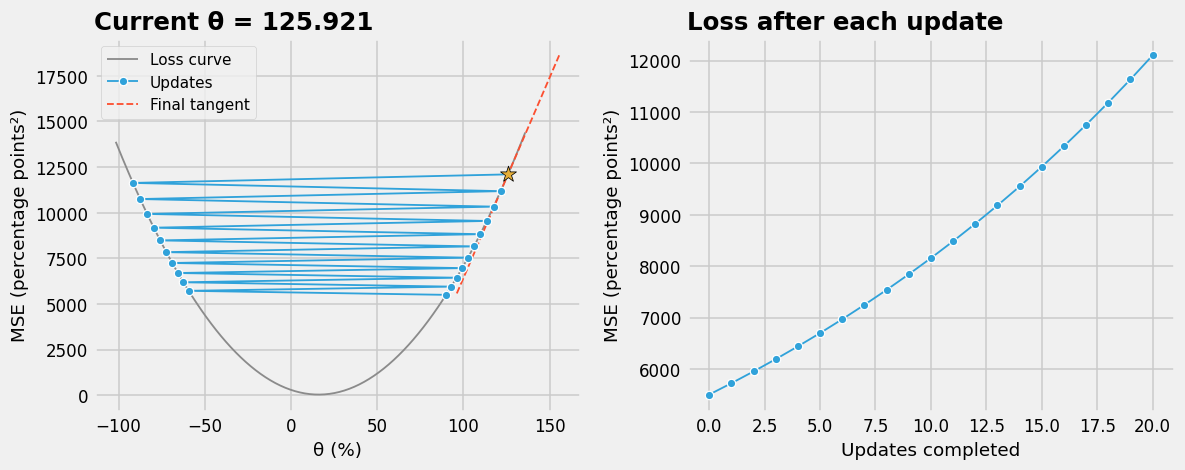

In [11]:
show_constant(20)

<p>Takeaway: The update subtracts the gradient. Its direction alone does not guarantee improvement when the learning rate is too large.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="1D-Gradient--Descent"></a>
<a id="section3"></a><h2>3. 1D Gradient Descent</h2><p>Question: how does gradient descent fit a line with no intercept?</p>

<h3>Change from a constant to a slope</h3><p>Predict the tip amount from the bill using <code>tip = theta * total_bill</code>. There is one fitted parameter and the line is constrained to pass through the origin.</p>

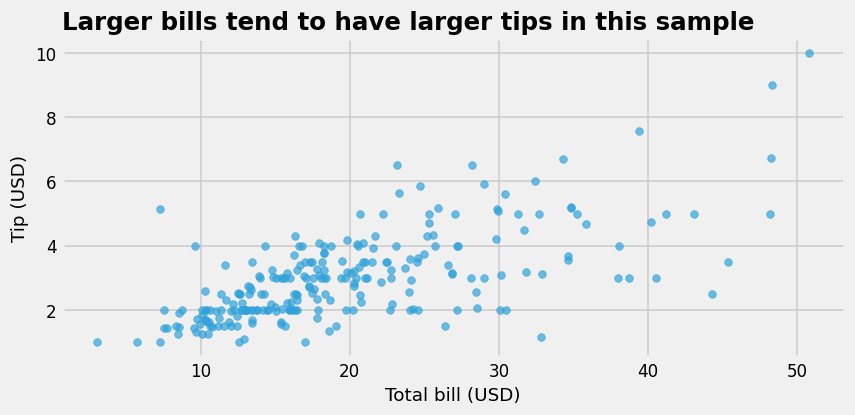

In [12]:
x = tips['total_bill'].to_numpy()
y_obs = tips['tip'].to_numpy()
utils.plot_bill_tip(x, y_obs)

<h3>Differentiate the line-model loss</h3><p>The feature value multiplies the residual in the gradient. The appropriate learning rate therefore depends on the scale of the bill values.</p>

In [13]:
def mse_1d(theta, x, y_obs):
    y_hat = theta * x
    return np.mean((y_hat - y_obs)**2)

def grad_mse_1d(theta, x, y_obs):
    y_hat = theta * x
    return np.mean(2 * (y_hat - y_obs) * x)

<h3>Run the one-parameter updates</h3><p>Retain the original starting slope of 90 and rate of 0.0005. The loop below calculates every update. The helper displays the loss curve, history, fitted line and residual segments.</p>

In [14]:
def trace_1d(steps, x, y_obs, alpha=0.0005, start=90.0):
    theta = float(start)
    path = [theta]
    for _ in range(steps):
        gradient = grad_mse_1d(theta, x, y_obs)
        theta = theta - alpha * gradient
        path.append(theta)
    losses = np.array([mse_1d(t, x, y_obs) for t in path])
    gradients = np.array([grad_mse_1d(t, x, y_obs) for t in path])
    return np.array(path), losses, gradients

In [15]:
def show_1d(epochs):
    path, losses, gradients = trace_1d(epochs, x, y_obs)
    grid = np.linspace(min(path)-1, max(path)+1, 250)
    curve = [mse_1d(t, x, y_obs) for t in grid]
    utils.plot_scalar_path(path, losses, gradients, grid, curve, x=x, y=y_obs)

interact(show_1d, epochs=IntSlider(value=1, min=1, max=20, continuous_update=False));

interactive(children=(IntSlider(value=1, continuous_update=False, description='epochs', max=20, min=1), Output…

<p>The static view records the original 20-update comparison. A logarithmic loss axis shows the large initial reduction without hiding later progress.</p>

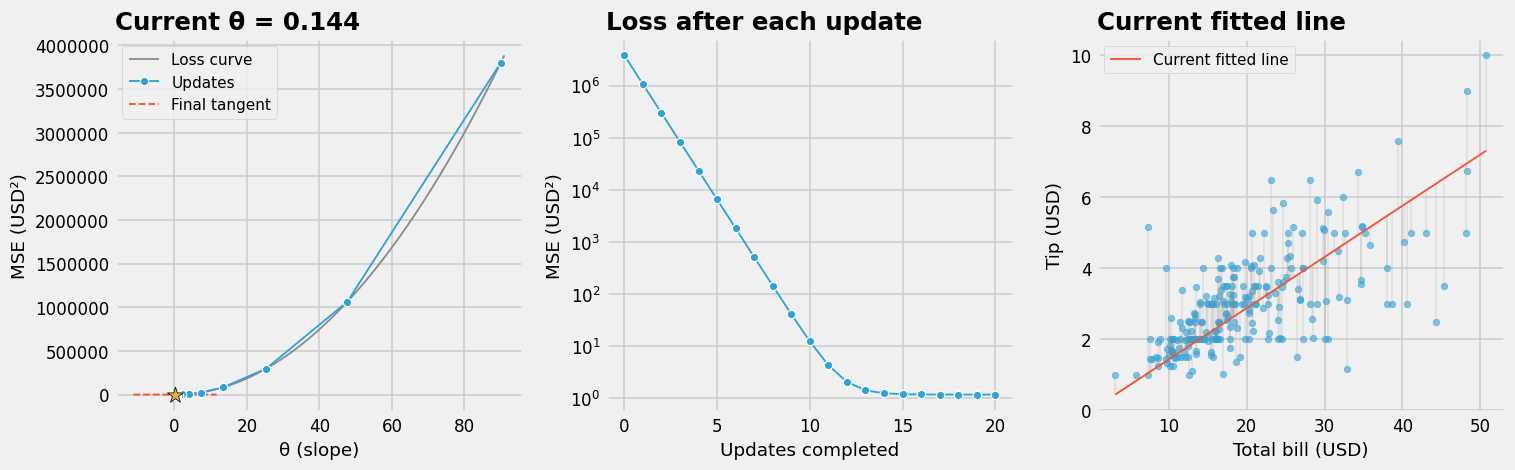

In [16]:
show_1d(20)

<h3>Check against the exact one-slope fit</h3><p>The least-squares slope through the origin equals the sum of x times y divided by the sum of x squared. This check assesses optimization on the fitted sample, rather than prediction on future bills.</p>

In [17]:
path_1d, loss_1d, _ = trace_1d(60, x, y_obs)
closed_slope = np.sum(x * y_obs) / np.sum(x**2)
print(f'Gradient descent slope: {path_1d[-1]:.6f}')
print(f'Closed-form slope: {closed_slope:.6f}')

Gradient descent slope: 0.143683
Closed-form slope: 0.143683


<p>Takeaway: The model changes the gradient formula. The parameter update retains the same subtraction rule.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="2D-Gradient--Descent-(Unscaled)"></a>
<a id="section4"></a><h2>4. 2D Gradient Descent (Unscaled)</h2><p>Question: what changes when the model has an intercept and a slope?</p>

<h3>Calculate both gradient components</h3><p>Predict <code>theta0 + theta1 * x</code>. The intercept derivative averages residuals. The slope derivative averages residuals multiplied by the feature. Both gradients use the same current parameters.</p>

In [18]:
def mse_2d(theta0, theta1, x, y_obs):
    y_hat = theta0 + theta1 * x
    return np.mean((y_hat - y_obs)**2)

def grad_mse_2d(theta0, theta1, x, y_obs):
    y_hat = theta0 + theta1 * x
    grad_0 = -2 * np.mean(y_obs - y_hat)
    grad_1 = -2 * np.mean(x * (y_obs - y_hat))
    return grad_0, grad_1

<h3>Update both parameters together</h3><p>The starting values are 10 and 10 in the unscaled example. Record the whole-data loss before and after each update. The loop remains visible and is reused for the scaled example.</p>

In [19]:
def trace_line(steps, x, y_obs, alpha=0.0005, start=(10.0, 10.0)):
    theta0, theta1 = start
    path = [(theta0, theta1)]
    losses = [mse_2d(theta0, theta1, x, y_obs)]
    for _ in range(steps):
        gradient_0, gradient_1 = grad_mse_2d(theta0, theta1, x, y_obs)
        new_theta0 = theta0 - alpha * gradient_0
        new_theta1 = theta1 - alpha * gradient_1
        theta0, theta1 = new_theta0, new_theta1
        path.append((theta0, theta1))
        losses.append(mse_2d(theta0, theta1, x, y_obs))
    return np.array(path), np.array(losses)

In [20]:
def show_unscaled(epochs):
    path, losses = trace_line(epochs, x, y_obs)
    utils.plot_line_path(path, losses, x, y_obs, mse_2d)

interact(show_unscaled, epochs=IntSlider(value=1, min=1, max=100000,
                                        continuous_update=False));

interactive(children=(IntSlider(value=1, continuous_update=False, description='epochs', max=100000, min=1), Ou…

<p>Each contour connects parameter pairs with equal MSE. The surface displays the same objective in three dimensions. The saved view below records 10,000 updates. The log loss axis includes the large initial loss.</p>

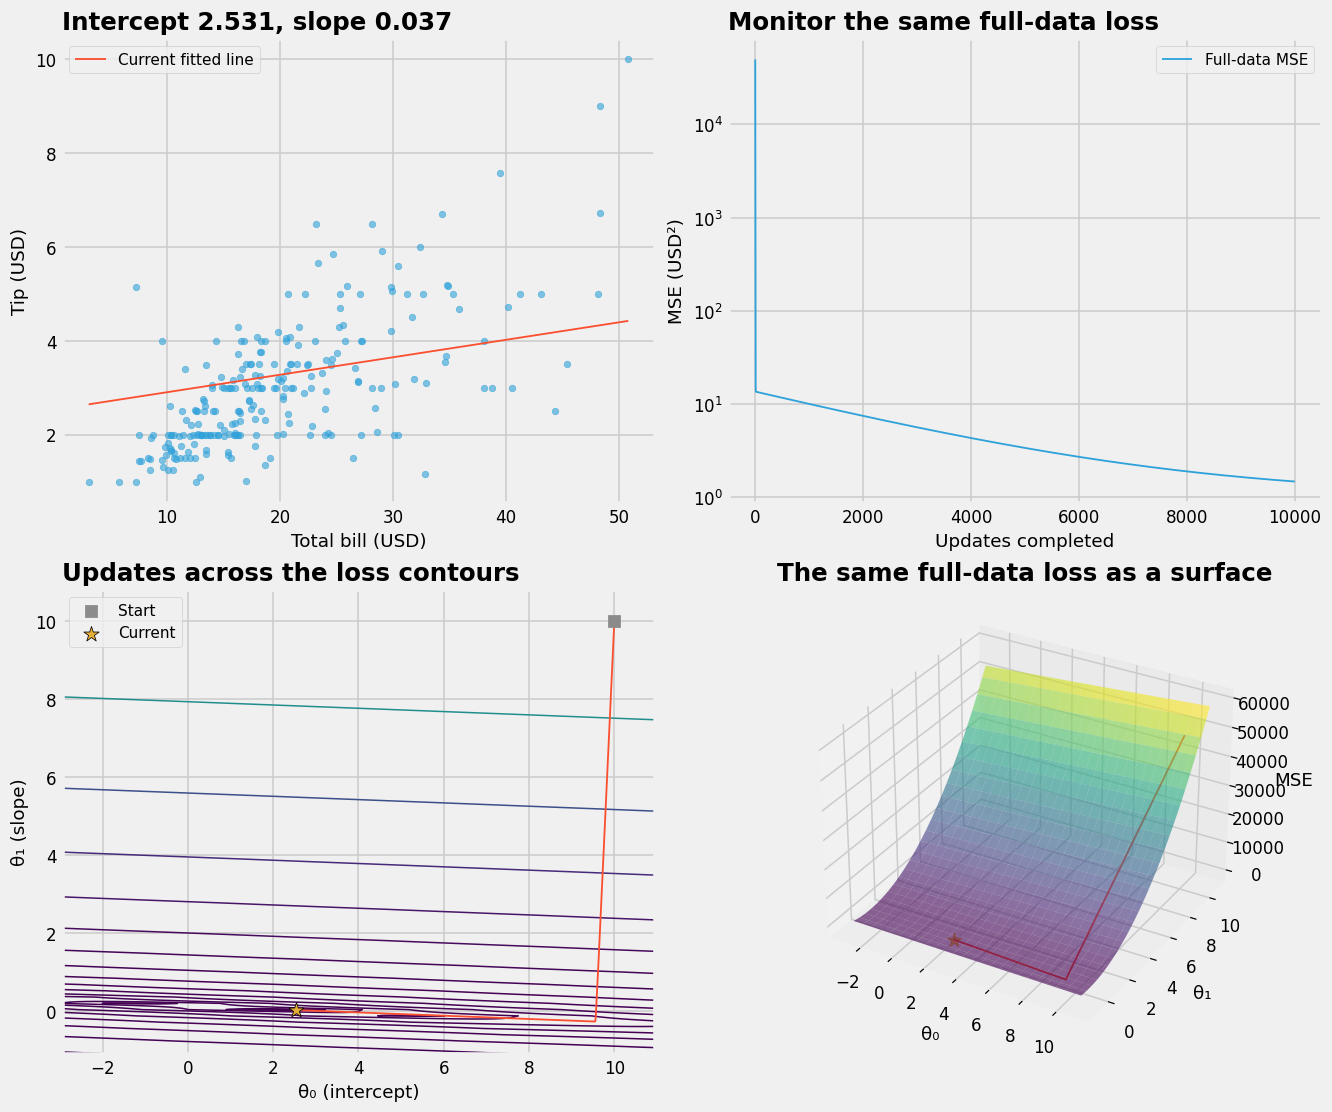

In [21]:
show_unscaled(10000)

<p>Takeaway: Parameters interact through the objective. Different curvature across directions makes one shared learning rate progress unevenly.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="2D-Gradient--Descent-(Scaled)"></a>
<a id="section5"></a><h2>5. 2D Gradient Descent (Scaled)</h2><p>Question: how does rescaling change the optimization path?</p>

<h3>Expose the scaling calculation</h3><p>Retain the original transformation of both the bill and tip: subtract each mean and divide by its standard deviation. These are standardized values, so the displayed loss no longer has dollar-squared units.</p>

In [22]:
x_scaled = (x - x.mean()) / x.std()
y_scaled = (y_obs - y_obs.mean()) / y_obs.std()
print('Scaled feature mean and standard deviation:', x_scaled.mean().round(6), x_scaled.std().round(6))

Scaled feature mean and standard deviation: 0.0 1.0


<h3>Reuse the same two-parameter update</h3><p>Use the same gradient formulas with standardized inputs. The original starting values are 12.5 and 7.5, with learning rate 0.2. The larger rate is suitable for this changed objective scale.</p>

In [23]:
def show_scaled(epochs):
    path, losses = trace_line(epochs, x_scaled, y_scaled,
                              alpha=0.2, start=(12.5, 7.5))
    utils.plot_line_path(path, losses, x_scaled, y_scaled, mse_2d, scaled=True)

interact(show_scaled, epochs=IntSlider(value=1, min=1, max=100,
                                      continuous_update=False));

interactive(children=(IntSlider(value=1, continuous_update=False, description='epochs', min=1), Output()), _do…

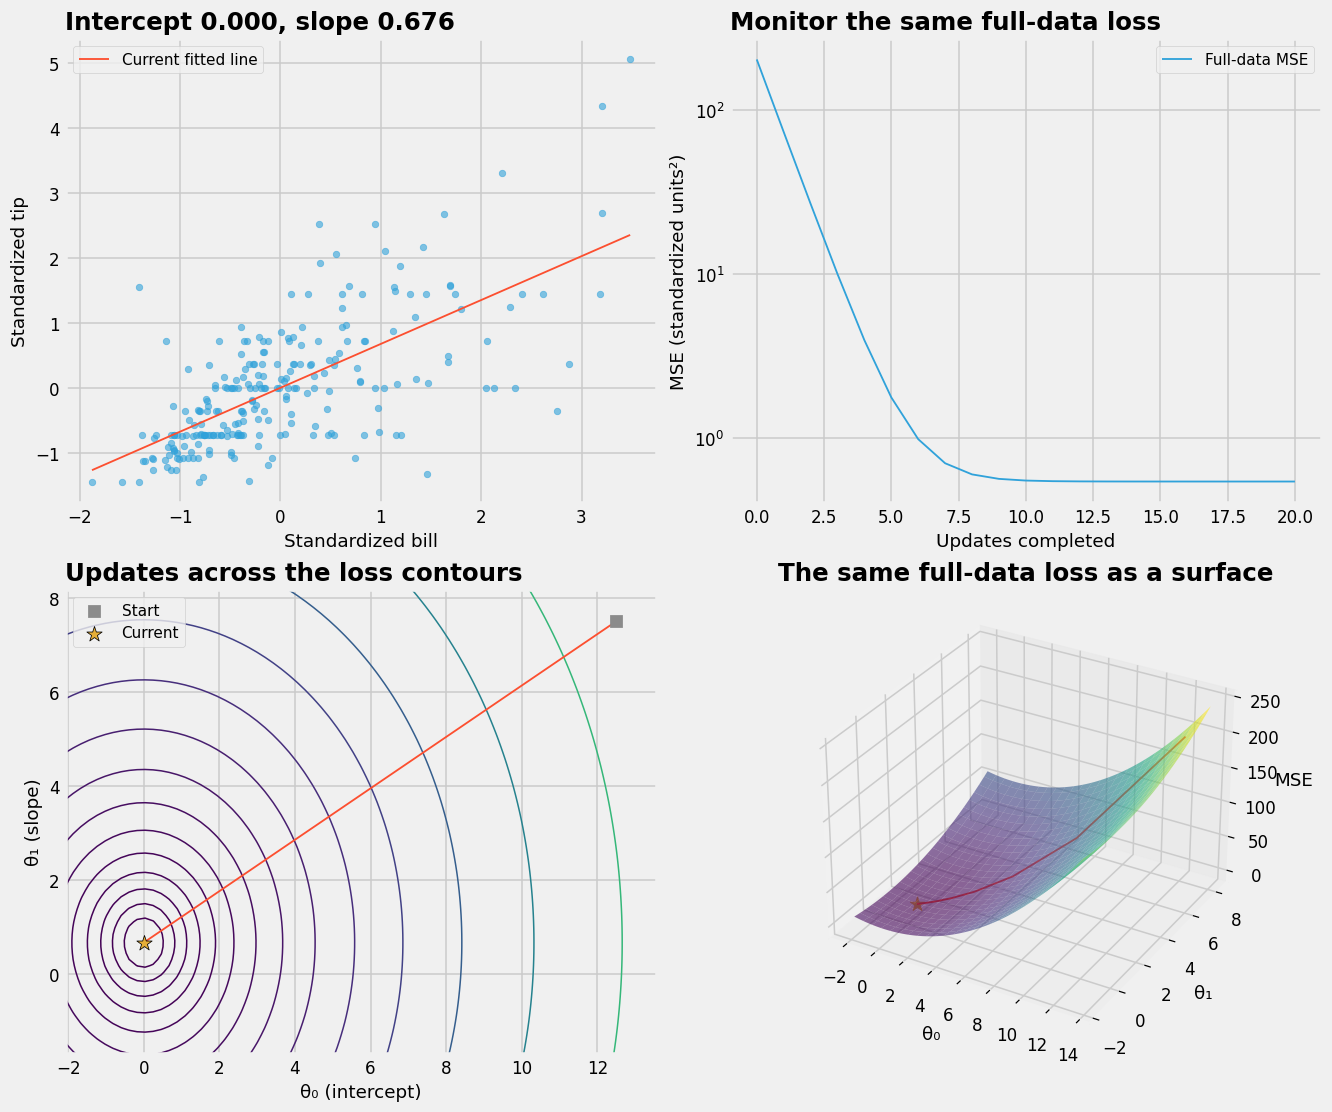

In [24]:
show_scaled(20)

<p>Standardizing this single feature makes its quadratic objective round in these parameter coordinates. With several correlated features, standardization alone does not guarantee a round objective. The raw and scaled panels also use different starting predictions and loss units, so their heights are not a controlled speed comparison.</p>

<p>Takeaway: Scaling changes the optimization coordinates. Keep the transformation, starting point, learning rate and loss units explicit when comparing runs.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="lecture-summary"></a><h2>Lecture summary</h2><ul><li>The gradient describes the local change of loss with each parameter.</li><li>Each update subtracts the learning rate times the current gradient.</li><li>Record losses at the same parameters shown in the path.</li><li>Feature scale affects which learning rates are stable.</li><li>A least-squares solution checks optimization without proving generalization.</li></ul>

<a id="section6"></a><h2>6. Inspect each update and learning rate</h2><p>Optional extension.</p><p>Question: how do the gradient sign and learning rate determine the next value?</p>

<h3>Read the first six updates</h3><p>Use the constant tips model with a starting prediction of 40%. The table exposes the current parameter, gradient and loss. The change to the next row equals minus 0.2 times the current gradient.</p>

In [25]:
path, losses, gradients = trace_constant(6, mse_constant, grad_mse_constant,
    tips['tip_pct'].to_numpy(), alpha=0.2, start=40)
updates = pd.DataFrame({'step': np.arange(len(path)), 'theta': path,
                        'gradient': gradients, 'loss': losses})
updates.round(4)

,step,theta,gradient,loss
0,0,40.0000,47.8386,609.4313
1,1,30.4323,28.7032,243.2661
2,2,24.6916,17.2219,111.4466
3,3,21.2473,10.3331,63.9915
4,4,19.1806,6.1999,46.9077
5,5,17.9407,3.7199,40.7576
6,6,17.1967,2.2320,38.5435


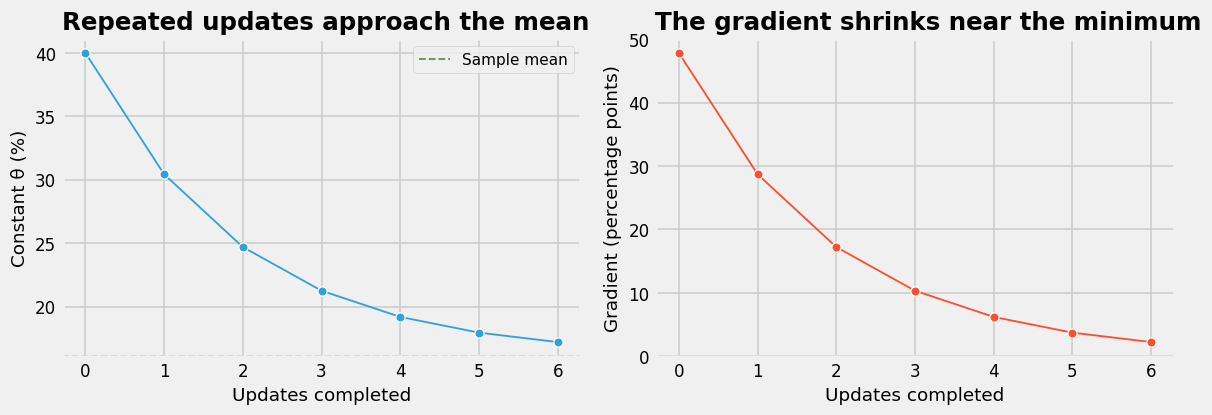

In [26]:
utils.plot_update_steps(updates, tips['tip_pct'].mean())

<h3>Check the derivative numerically</h3><p>A centred finite difference approximates the derivative from two nearby loss evaluations. Agreement with the analytical gradient checks the sign and scale of the formula at this parameter.</p>

In [27]:
probe = 20.0
epsilon = 1e-5
values = tips['tip_pct'].to_numpy()
numerical_gradient = (mse_constant(probe+epsilon, values)
                      - mse_constant(probe-epsilon, values)) / (2*epsilon)
print('Analytical gradient:', grad_mse_constant(probe, values))
print('Finite-difference gradient:', numerical_gradient)

Analytical gradient: 7.838612731402911
Finite-difference gradient: 7.83861273063735


<h3>Hold the starting point fixed</h3><p>Run 30 updates for each rate, using the same starting constant. For this quadratic, the error relative to the mean is multiplied by <code>1 - 2 * alpha</code> on each update. Rates between zero and one converge. Rates above one diverge except when already at the minimum.</p>

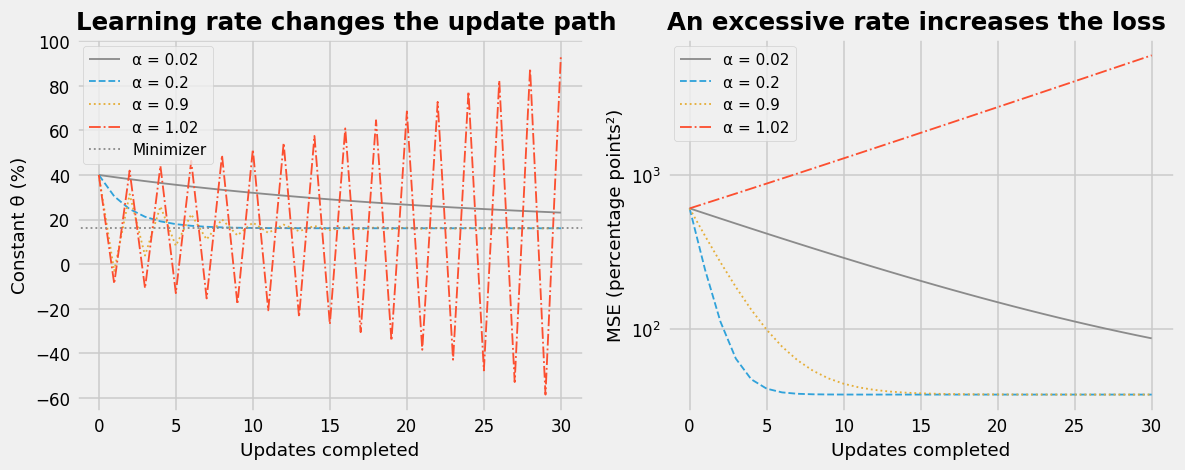

In [28]:
rate_paths, rate_losses = {}, {}
for rate in [0.02, 0.2, 0.9, 1.02]:
    rate_paths[rate], rate_losses[rate], _ = trace_constant(30,
        mse_constant, grad_mse_constant, values, alpha=rate, start=40)
utils.plot_learning_rates(rate_paths, rate_losses, values.mean())

<p>Takeaway: A gradient check verifies the local formula. A learning-rate comparison checks the behaviour of repeated updates on the chosen objective.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="section7"></a><h2>7. Fit a sensor response</h2><p>Optional extension.</p><p>Question: does the same two-parameter loop fit a different dataset?</p>

<h3>Load a constructed calibration table</h3><p>Each row pairs a reference pressure with a sensor reading and temperature. The 96 rows are generated teaching data, with a known offset, gain and temperature effect. They are not measurements from a real instrument.</p>

In [29]:
calibration = pd.read_csv('illustrative_sensor_calibration.csv')
pressure = calibration['reference_kpa'].to_numpy()
reading = calibration['sensor_kpa'].to_numpy()
calibration.head()

,reference_kpa,temperature_c,sensor_kpa
0,125.1007,30.0127,142.8188
1,211.6221,23.0572,233.1352
2,189.5266,15.8176,207.6651
3,20.6806,21.4629,30.1319
4,67.0114,33.7016,83.4898


<h3>Scale only the input feature</h3><p>Keep the response in kPa for both runs and start both predicted lines at zero. This makes their MSE values comparable. The different learning rates reflect the different feature scales.</p>

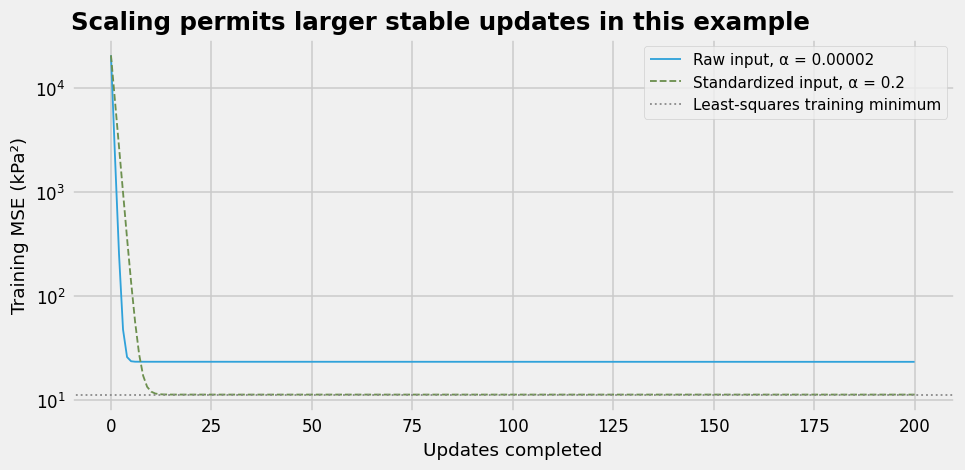

In [30]:
pressure_mean, pressure_std = pressure.mean(), pressure.std()
pressure_scaled = (pressure - pressure_mean) / pressure_std
raw_path, raw_loss = trace_line(200, pressure, reading, alpha=0.00002, start=(0, 0))
cal_path, cal_loss = trace_line(200, pressure_scaled, reading, alpha=0.2, start=(0, 0))
design = np.column_stack([np.ones(len(pressure)), pressure_scaled])
least_squares = np.linalg.lstsq(design, reading, rcond=None)[0]
minimum_loss = np.mean((design @ least_squares - reading)**2)
utils.plot_training_curves({'Raw input, α = 0.00002': raw_loss,
    'Standardized input, α = 0.2': cal_loss}, minimum_loss,
    'Scaling permits larger stable updates in this example')

<p>Both curves measure MSE in kPa squared on the same fitted rows. The comparison illustrates these settings rather than a universal speed ranking or a test of future prediction.</p>

<h3>Return the coefficients to pressure units</h3><p>Convert the fitted slope and intercept back from standardized input coordinates. The prediction is the sensor response to a reference pressure, rather than an inverse correction for an unknown pressure.</p>

Fitted response: sensor_kpa = 7.667 + 1.058 × reference_kpa
Parameter agreement with least squares: True


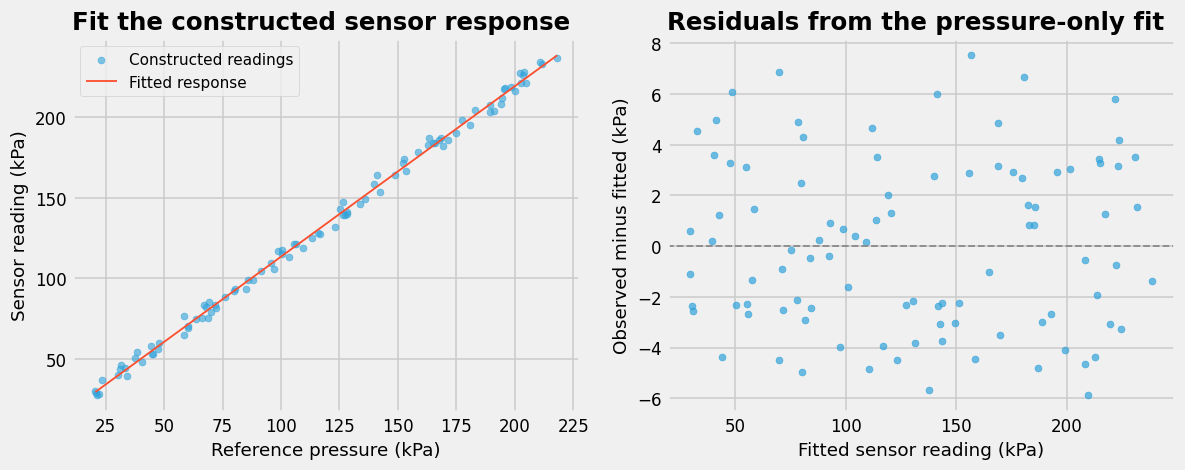

In [31]:
cal_theta = cal_path[-1]
raw_slope = cal_theta[1] / pressure_std
raw_intercept = cal_theta[0] - raw_slope * pressure_mean
cal_predictions = cal_theta[0] + cal_theta[1] * pressure_scaled
print(f'Fitted response: sensor_kpa = {raw_intercept:.3f} + {raw_slope:.3f} × reference_kpa')
print('Parameter agreement with least squares:', np.allclose(cal_theta, least_squares))
utils.plot_calibration(calibration, cal_predictions)

<p>Takeaway: The loop transfers to another linear fitting problem. Retain units and compare against a known numerical solution.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="section8"></a><h2>8. Extend the gradient to several features</h2><p>Optional extension.</p><p>Question: what changes when temperature becomes a second input?</p>

<h3>Build a three-parameter model</h3><p>Add a standardized temperature column alongside the intercept and standardized pressure. The matrix product <code>X @ theta</code> computes every prediction. Temperature affects the constructed response, so this extension tests a known signal.</p>

In [32]:
temperature = calibration['temperature_c'].to_numpy()
temperature_scaled = (temperature - temperature.mean()) / temperature.std()
X = np.column_stack([np.ones(len(reading)), pressure_scaled, temperature_scaled])
print('Design matrix shape:', X.shape)

def matrix_loss(theta, X, y):
    return np.mean((X @ theta - y)**2)

def matrix_gradient(theta, X, y):
    return 2 / len(y) * X.T @ (X @ theta - y)

Design matrix shape: (96, 3)


<h3>Run the vector update</h3><p>There is one gradient component per parameter. The same subtraction updates the whole vector at once. The loop and the matrix gradient stay visible.</p>

In [33]:
theta = np.zeros(X.shape[1])
multifeature_losses = [matrix_loss(theta, X, reading)]
for step in range(200):
    gradient = matrix_gradient(theta, X, reading)
    theta = theta - 0.1 * gradient
    multifeature_losses.append(matrix_loss(theta, X, reading))
closed = np.linalg.lstsq(X, reading, rcond=None)[0]
print('Gradient descent:', theta.round(5))
print('Least squares:   ', closed.round(5))

Gradient descent: [130.22423  62.49403   2.97863]
Least squares:    [130.22423  62.49403   2.97863]


<h3>Inspect the remaining errors</h3><p>Compare the residuals with temperature before and after adding the temperature term. All results use the fitted sample. A separate validation design would be required to assess performance on new sensor readings.</p>

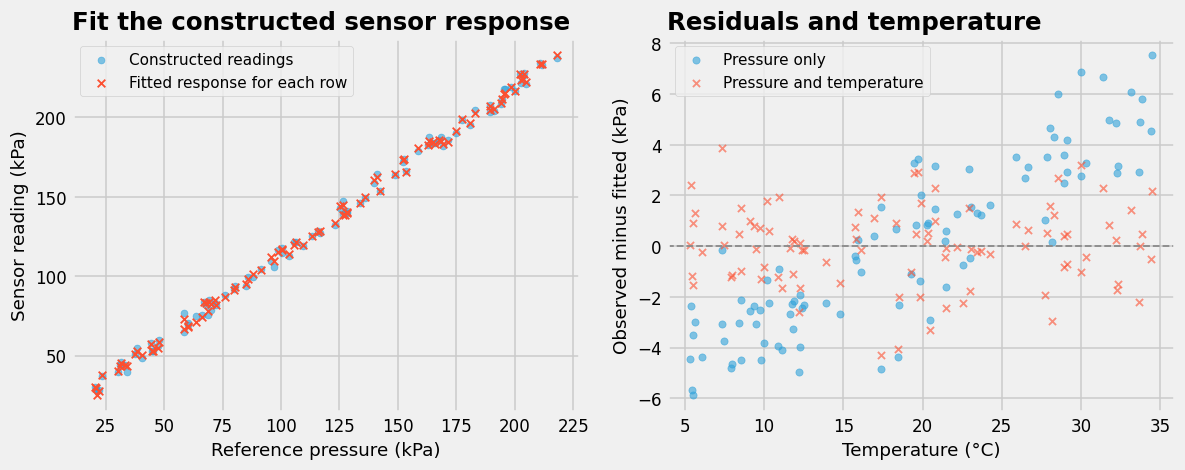

Pressure-only training MSE: 11.262
Two-feature training MSE: 2.411


In [34]:
multifeature_predictions = X @ theta
residuals = {'Pressure only': reading-cal_predictions,
             'Pressure and temperature': reading-multifeature_predictions}
utils.plot_calibration(calibration, multifeature_predictions, residuals=residuals)
print('Pressure-only training MSE:', round(np.mean(residuals['Pressure only']**2), 3))
print('Two-feature training MSE:', round(matrix_loss(theta, X, reading), 3))

<p>Takeaway: Additional features lengthen the parameter and gradient vectors. The optimization rule remains unchanged.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>